In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet152V2
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# Set dataset path
base_dir = '/content/drive/MyDrive/data'

# Image preprocessing
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 321 images belonging to 2 classes.
Found 81 images belonging to 2 classes.
Found 71 images belonging to 2 classes.


In [ ]:

# Load pre-trained ResNet152V2 model (excluding top classification layer)
base_model = ResNet152V2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

# Freeze the base model layers
for layer in base_model.layers:
    layer.trainable = False

# Add custom classification layers
x = base_model.output
x = Flatten()(x)
x = Dense(4096, activation='relu')(x)
x = Dense(4096, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)  # Assuming 2 classes: Flood, Non-Flood

# Create the new model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
 3/11 ━━━━━━━━━━━━━━━━━━━━ 3:07 23s/step - accuracy: 0.8073 - loss: 0.5093

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


11/11 ━━━━━━━━━━━━━━━━━━━━ 320s 27s/step - accuracy: 0.8720 - loss: 0.8566 - val_accuracy: 0.8889 - val_loss: 1.2701
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 282s 26s/step - accuracy: 0.9871 - loss: 0.2574 - val_accuracy: 0.8889 - val_loss: 1.5119
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 322s 26s/step - accuracy: 0.9845 - loss: 0.1541 - val_accuracy: 0.8889 - val_loss: 3.8948
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 279s 26s/step - accuracy: 0.9900 - loss: 0.0804 - val_accuracy: 0.9383 - val_loss: 1.4086
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 279s 27s/step - accuracy: 0.9966 - loss: 0.0288 - val_accuracy: 0.9136 - val_loss: 1.2946
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 278s 27s/step - accuracy: 0.9951 - loss: 0.0551 - val_accuracy: 0.9259 - val_loss: 2.3369
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 324s 26s/step - accuracy: 0.9964 - loss: 0.0227 - val_accuracy: 0.9383 - val_loss: 0.9527
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 276s 25s/step - accuracy: 1.0000 - loss: 9.6269e-11 - val_accuracy: 0.9259 - 

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {accuracy:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 36s 10s/step - accuracy: 0.9437 - loss: 3.2369
Test Accuracy: 0.96


In [ ]:
# Save the model
model_save_path = '/content/drive/MyDrive/pre_trained_resnet152v2_model.h5'
model.save(model_save_path)
print(f"Model saved successfully to {model_save_path}.")

# Verify if the file exists
import os
if os.path.exists(model_save_path):
    print("Model file found after saving.")
else:
    print("Error: Model file not found after saving.")

Model saved successfully to /content/drive/MyDrive/pre_trained_resnet152v2_model.h5.
Model file found after saving.


3/3 ━━━━━━━━━━━━━━━━━━━━ 56s 14s/step


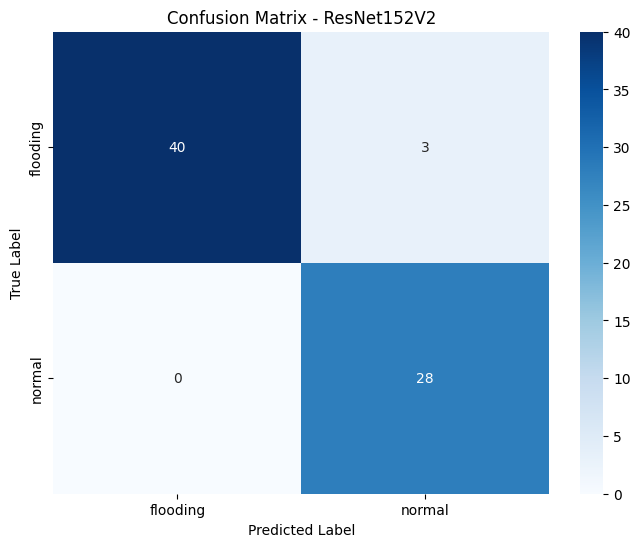

In [ ]:

# Generate and plot confusion matrix
predictions = model.predict(test_gen)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - ResNet152V2')
plt.show()

In [ ]:


# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Classification Report:
              precision    recall  f1-score   support

    flooding       1.00      0.93      0.96        43
      normal       0.90      1.00      0.95        28

    accuracy                           0.96        71
   macro avg       0.95      0.97      0.96        71
weighted avg       0.96      0.96      0.96        71

